# Mask R-CNN Demo

A quick intro to using the pre-trained model to detect and segment objects.

In [1]:
import os
import sys
import random
import math
import numpy as np
import skimage.io
import matplotlib
import matplotlib.pyplot as plt

# Root directory of the project
ROOT_DIR = os.path.abspath("../")

# Import Mask RCNN
sys.path.append(ROOT_DIR)  # To find local version of the library
from mrcnn import utils
import mrcnn.model as modellib
from mrcnn import visualize
# Import COCO config
sys.path.append(os.path.join(ROOT_DIR, "samples/coco/"))  # To find local version
import coco

%matplotlib inline 

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT_DIR, "logs")

# Local path to trained weights file
COCO_MODEL_PATH = os.path.join(ROOT_DIR, "mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

# Directory of images to run detection on
IMAGE_DIR = os.path.join(ROOT_DIR, "images")

Using TensorFlow backend.


... done downloading pretrained model!


## Configurations

We'll be using a model trained on the MS-COCO dataset. The configurations of this model are in the ```CocoConfig``` class in ```coco.py```.

For inferencing, modify the configurations a bit to fit the task. To do so, sub-class the ```CocoConfig``` class and override the attributes you need to change.

In [2]:
class InferenceConfig(coco.CocoConfig):
    # Set batch size to 1 since we'll be running inference on
    # one image at a time. Batch size = GPU_COUNT * IMAGES_PER_GPU
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1

config = InferenceConfig()
config.display()


Configurations:
BACKBONE                       resnet101
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     1
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        100
DETECTION_MIN_CONFIDENCE       0.7
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 1
IMAGE_MAX_DIM                  1024
IMAGE_META_SIZE                93
IMAGE_MIN_DIM                  800
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              square
IMAGE_SHAPE                    [1024 1024    3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE                     [28, 28]
MAX_GT_INSTA

## Create Model and Load Trained Weights

In [3]:
# Create model object in inference mode.
model = modellib.MaskRCNN(mode="inference", model_dir=MODEL_DIR, config=config)

# Load weights trained on MS-COCO
model.load_weights(COCO_MODEL_PATH, by_name=True)

## Class Names

The model classifies objects and returns class IDs, which are integer value that identify each class. Some datasets assign integer values to their classes and some don't. For example, in the MS-COCO dataset, the 'person' class is 1 and 'teddy bear' is 88. The IDs are often sequential, but not always. The COCO dataset, for example, has classes associated with class IDs 70 and 72, but not 71.

To improve consistency, and to support training on data from multiple sources at the same time, our ```Dataset``` class assigns it's own sequential integer IDs to each class. For example, if you load the COCO dataset using our ```Dataset``` class, the 'person' class would get class ID = 1 (just like COCO) and the 'teddy bear' class is 78 (different from COCO). Keep that in mind when mapping class IDs to class names.

To get the list of class names, you'd load the dataset and then use the ```class_names``` property like this.
```
# Load COCO dataset
dataset = coco.CocoDataset()
dataset.load_coco(COCO_DIR, "train")
dataset.prepare()

# Print class names
print(dataset.class_names)
```

We don't want to require you to download the COCO dataset just to run this demo, so we're including the list of class names below. The index of the class name in the list represent its ID (first class is 0, second is 1, third is 2, ...etc.)

In [4]:
# COCO Class names
# Index of the class in the list is its ID. For example, to get ID of
# the teddy bear class, use: class_names.index('teddy bear')
class_names = ['BG', 'person', 'bicycle', 'car', 'motorcycle', 'airplane',
               'bus', 'train', 'truck', 'boat', 'traffic light',
               'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird',
               'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear',
               'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie',
               'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
               'kite', 'baseball bat', 'baseball glove', 'skateboard',
               'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup',
               'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
               'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza',
               'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed',
               'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote',
               'keyboard', 'cell phone', 'microwave', 'oven', 'toaster',
               'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors',
               'teddy bear', 'hair drier', 'toothbrush']

## Run Object Detection

Processing 1 images
image                    shape: (394, 640, 3)         min:    0.00000  max:  255.00000  uint8
molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  150.10000  float64
image_metas              shape: (1, 93)               min:    0.00000  max: 1024.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


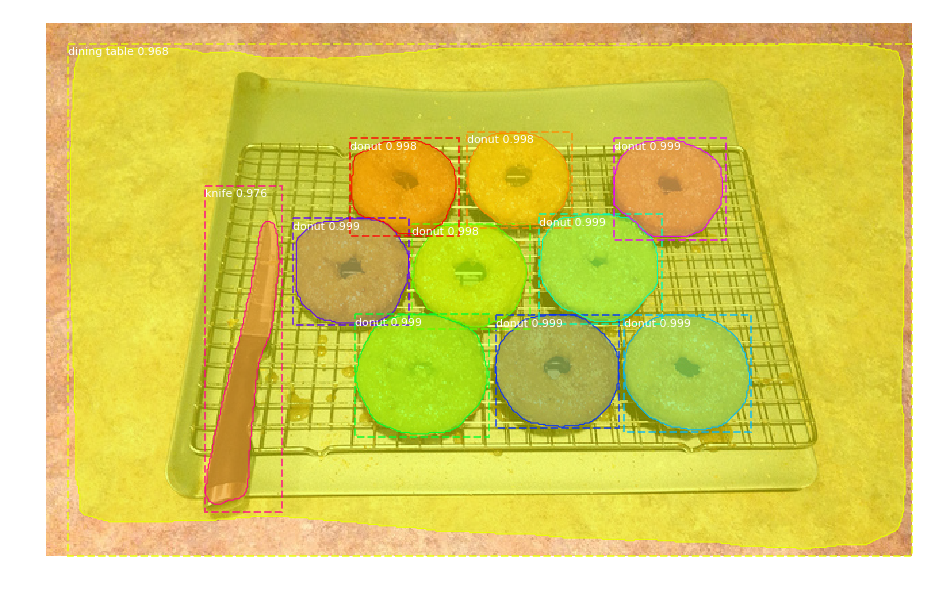

In [5]:
# Load a random image from the images folder
file_names = next(os.walk(IMAGE_DIR))[2]
image = skimage.io.imread(os.path.join(IMAGE_DIR, random.choice(file_names)))

# Run detection
results = model.detect([image], verbose=1)

# Visualize results
r = results[0]
visualize.display_instances(image, r['rois'], r['masks'], r['class_ids'], 
                            class_names, r['scores'])

Processing 1 images
image                    shape: (4725, 7096, 3)       min:    0.00000  max:  255.00000  uint8


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  151.10000  float64
image_metas              shape: (1, 93)               min:    0.00000  max: 7096.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32


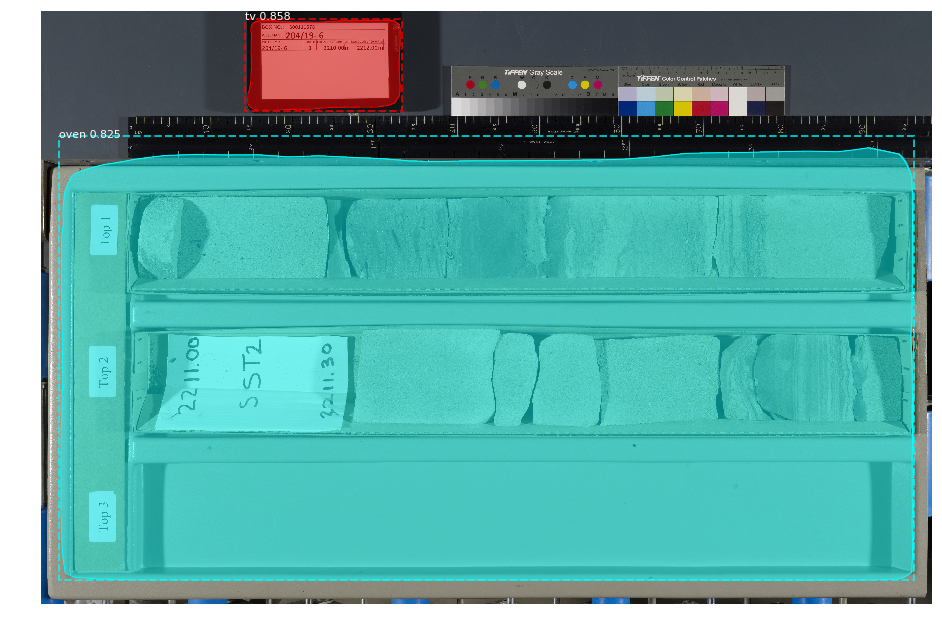

In [23]:
import glob
CORES_DIR = '/home/administrator/Dropbox/core_data/well_core_data/wos_data'

# Load a random image from the images folder
file_names = glob.glob(CORES_DIR+'/schiehallion-complex/204-19-6/converted/*jpeg')
image = skimage.io.imread(os.path.join(IMAGE_DIR, random.choice(file_names)))

# Run detection
results = model.detect([image], verbose=1)

# Visualize results
r = results[0]
visualize.display_instances(image, r['rois'], r['masks'], r['class_ids'], 
                            class_names, r['scores'])

In [10]:
results

[{'rois': array([[  60, 1631,  792, 2880],
         [ 994,  150, 4533, 6963]], dtype=int32),
  'class_ids': array([63, 70], dtype=int32),
  'scores': array([0.8581481, 0.8249753], dtype=float32),
  'masks': array([[[False, False],
          [False, False],
          [False, False],
          ...,
          [False, False],
          [False, False],
          [False, False]],
  
         [[False, False],
          [False, False],
          [False, False],
          ...,
          [False, False],
          [False, False],
          [False, False]],
  
         [[False, False],
          [False, False],
          [False, False],
          ...,
          [False, False],
          [False, False],
          [False, False]],
  
         ...,
  
         [[False, False],
          [False, False],
          [False, False],
          ...,
          [False, False],
          [False, False],
          [False, False]],
  
         [[False, False],
          [False, False],
          [False, False],


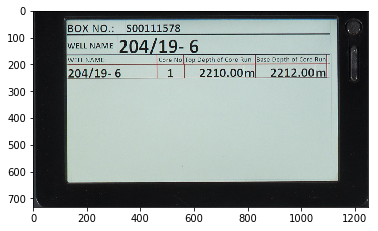

In [28]:
tv_class = 63

def crop_roi(img, roi):
    '''Return img[roi-coords].'''
    y1, x1, y2, x2 = tuple(roi)
    return img[y1:y2,x1:x2]

tv = crop_roi(image, r['rois'][0])
plt.imshow(tv)

In [15]:
from PIL import Image
import pytesseract

In [21]:
text = pytesseract.image_to_string(Image.fromarray(tv), nice=3)
print(text)

BOX NO.: 500111573

WELL NAME 204/19- 6

WE11 NAML, , [Core- PLngPepth of Core Run BarseﬂQer-pth M pore Run

204/19-6 ,1: 2210.001n1‘ 2212.00mJ


In [18]:
print(text)

BOX NO.: 500111573

WELL NAME 204/19- 6

WE11 NAML, , [Core- PLngPepth of Core Run BarseﬂQer-pth M pore Run

204/19-6 ,1: 2210.001n1‘ 2212.00mJ


Processing 1 images
image                    shape: (3539, 6813, 3)       min:    0.00000  max:  255.00000  uint8


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  150.10000  float64
image_metas              shape: (1, 93)               min:    0.00000  max: 6813.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32


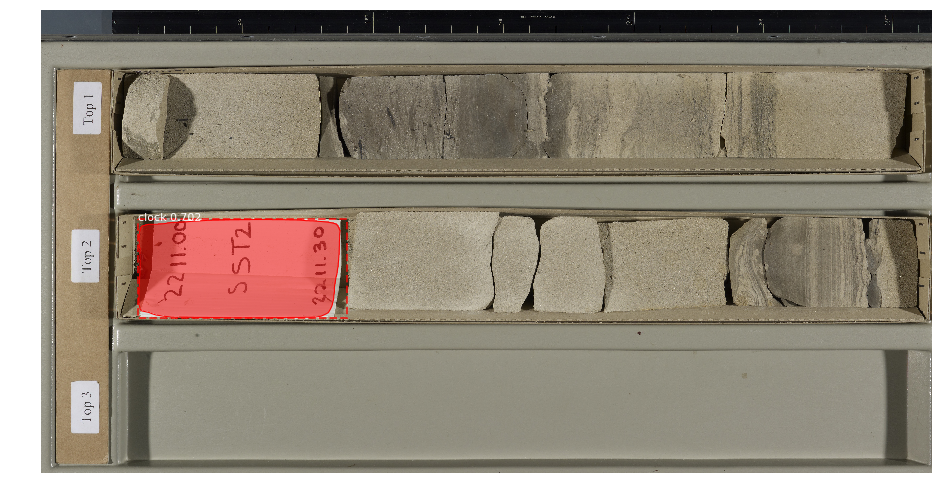

In [29]:
box_img = crop_roi(image, r['rois'][1])

results3 = model.detect([box_img], verbose=1)

# Visualize results
r3 = results3[0]
visualize.display_instances(box_img, r3['rois'], r3['masks'], r3['class_ids'], 
                            class_names, r3['scores'])

Processing 1 images
image                    shape: (1339, 6813, 3)       min:    0.00000  max:  255.00000  uint8


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  148.10000  float64
image_metas              shape: (1, 93)               min:    0.00000  max: 6813.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32

*** No instances to display *** 



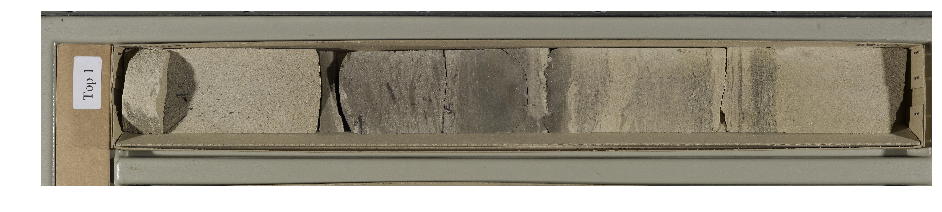

In [31]:
col_img = crop_roi(image, [994+200,  150, 4533-2000, 6963])

results3 = model.detect([col_img], verbose=1)

# Visualize results
r3 = results3[0]
visualize.display_instances(col_img, r3['rois'], r3['masks'], r3['class_ids'], 
                            class_names, r3['scores'])

In [57]:
from skimage import io, measure, morphology

from mrcnn.utils import extract_bboxes

In [36]:
def generate_mask(img, masking_color, morph_op=None):
    '''Generate a mask from a manually painted RGB image.
    
    Parameters
    ----------
    img : np.array, ndim=3
        RGB image as numpy array.
    masking_color : tuple, len=3
        (R, G, B) tuple to treat as TRUE pixel value
    morph_op : function (optional)
        Function to be applied to binary mask before returning
    Returns
    -------
    mask : np.array, ndim=2
        Binary mask, equivalent to where img == color
    '''

    R, G, B = masking_color

    reds, greens, blues = tuple(img[:, :, i] for i in range(3))
                
    mask = np.logical_and.reduce((reds==R, greens==G, blues==B))

    if morph_op:
        mask = morph_op(mask)

    return mask.astype(np.uint8)

def draw_box(image, box, color, lw):
    """Draw 3-pixel width bounding boxes on the given image array.
    color: list of 3 int values for RGB.
    """
    y1, x1, y2, x2 = box
    image[y1:y1 + lw, x1:x2] = color
    image[y2:y2 + lw, x1:x2] = color
    image[y1:y2, x1:x1 + lw] = color
    image[y1:y2, x2:x2 + lw] = color
    return image

In [69]:
BLUE_LABEL_DIR = '/home/administrator/Dropbox/core_data/segmentation/'

core_imgs = [io.imread(f) for f in sorted(glob.glob(BLUE_LABEL_DIR+'*.jpeg')) if 'BlueLabel' not in f]
label_imgs = [io.imread(f) for f in sorted(glob.glob(BLUE_LABEL_DIR+'*.jpeg')) if 'BlueLabel' in f]


[0 1 7 9]
[0 1 7 9]


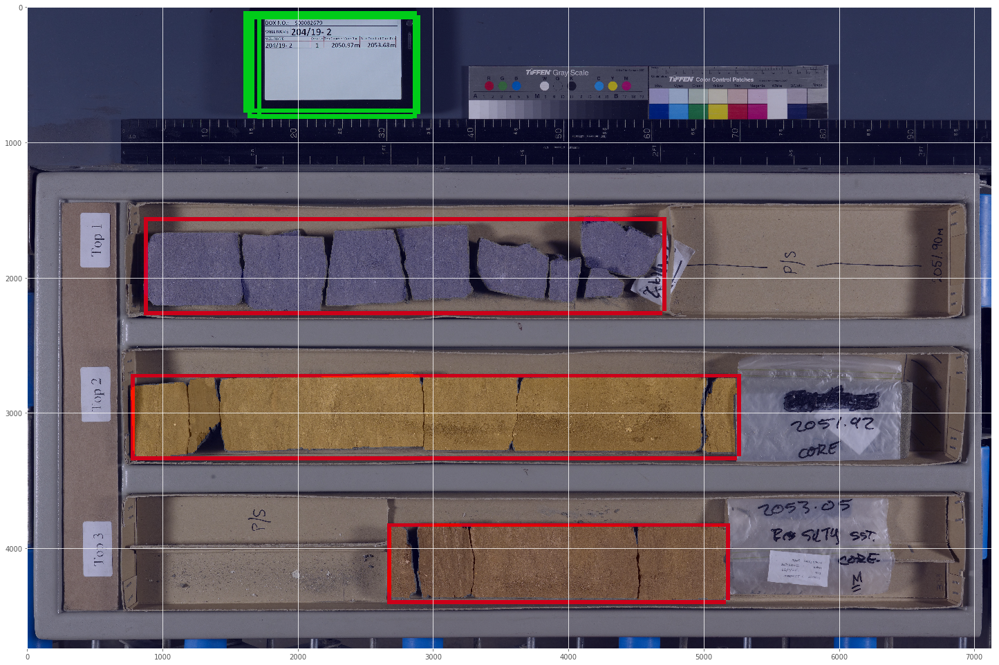

[0 1 4 6]
[0 1 4 6]


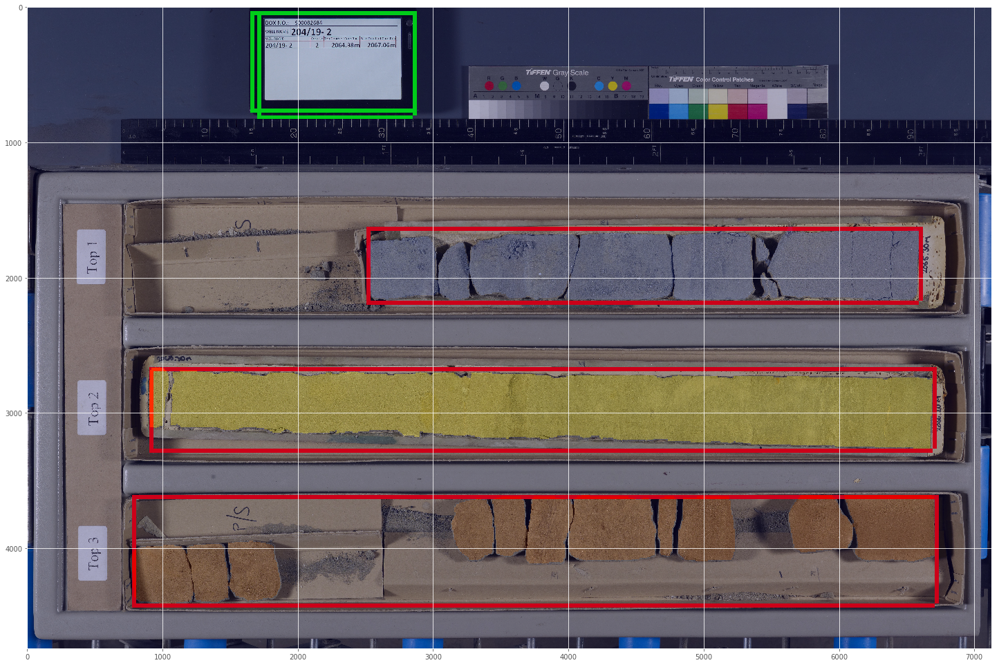

[0 1]
[0 1]


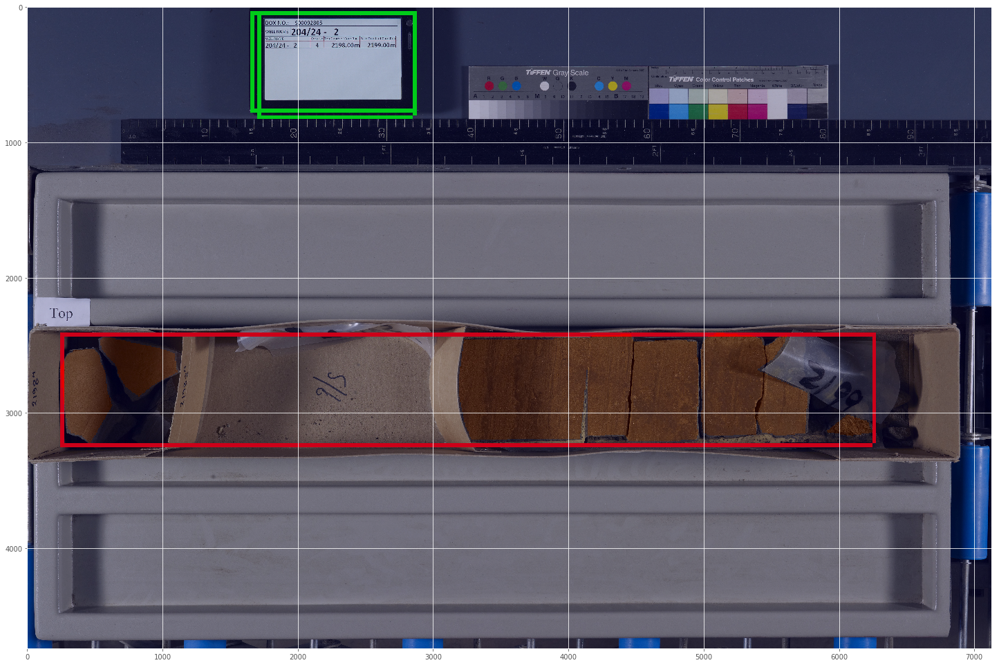

[0 1 7]
[0 1 7]


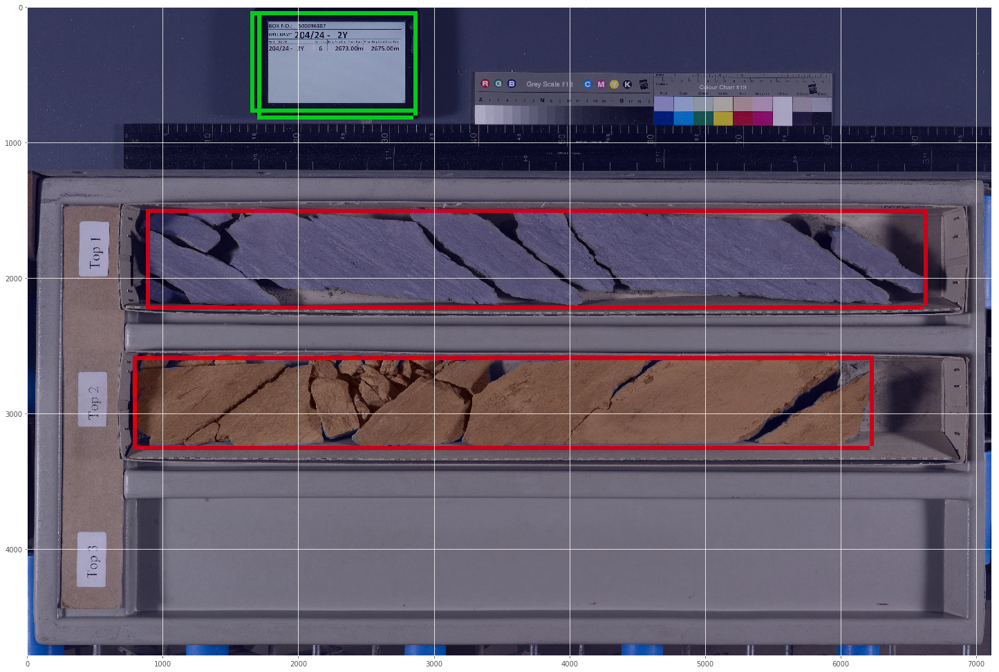

[0 1 2]
[0 1 2]


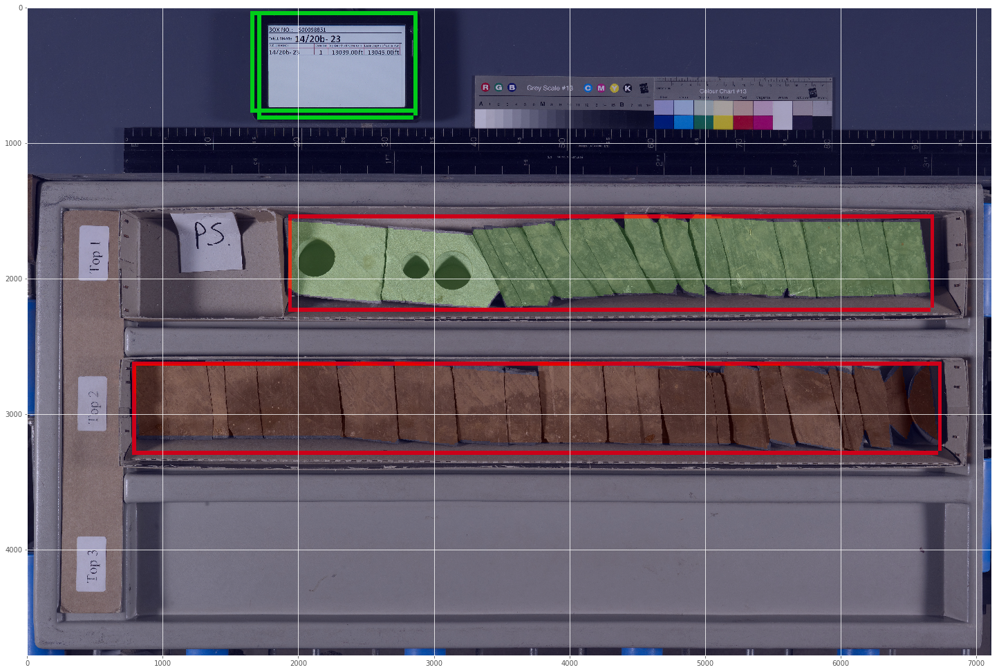

[0 1 2]
[0 1 2]


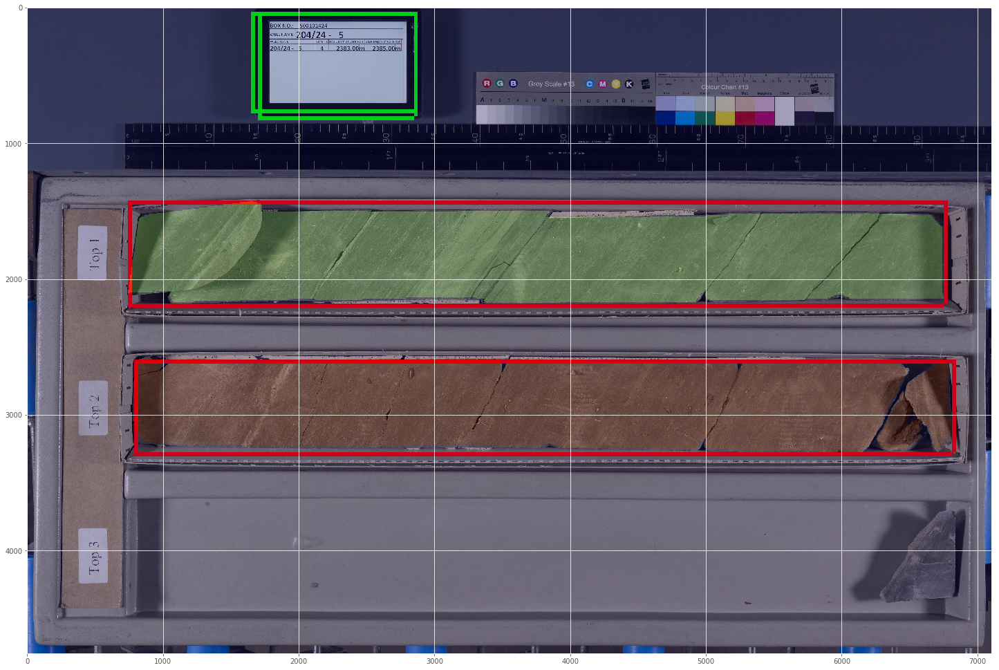

[0 1 2]
[0 1 2]


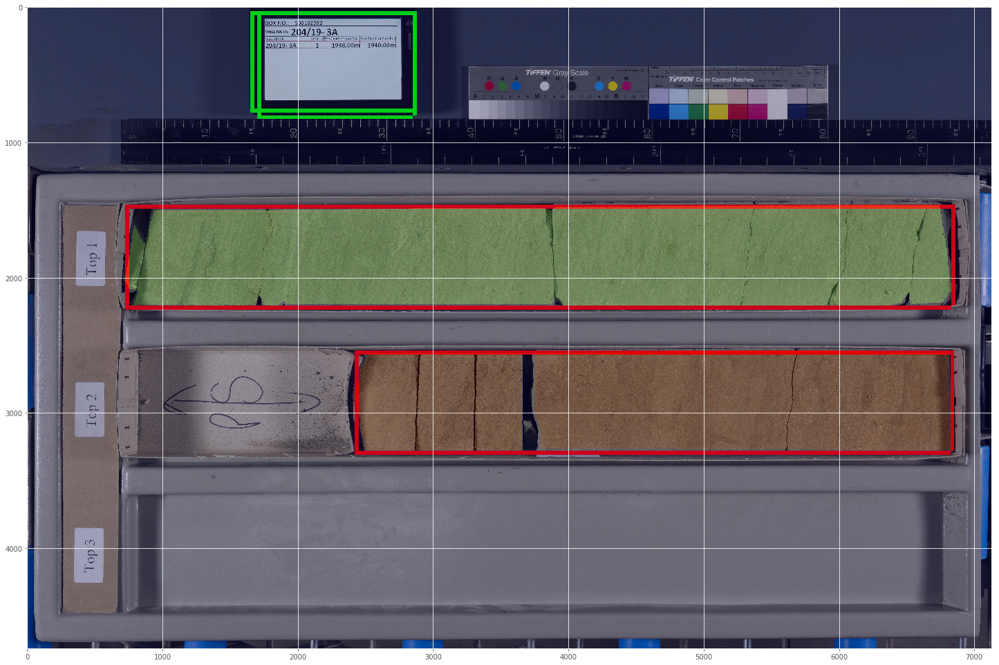

[0 1 2]
[0 1 2]


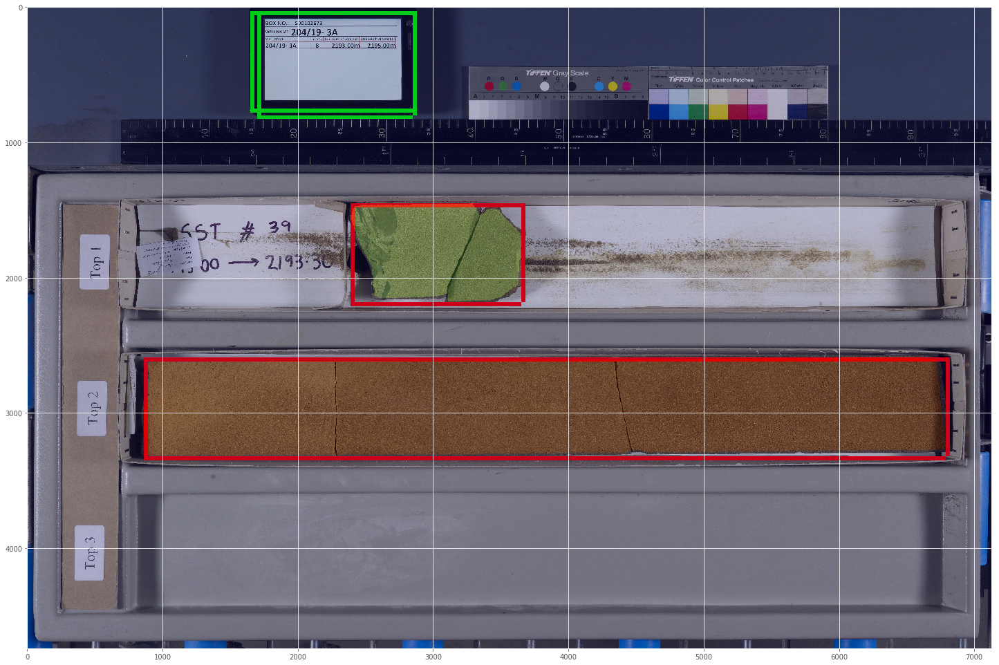

[0 1 2]
[0 1 2]


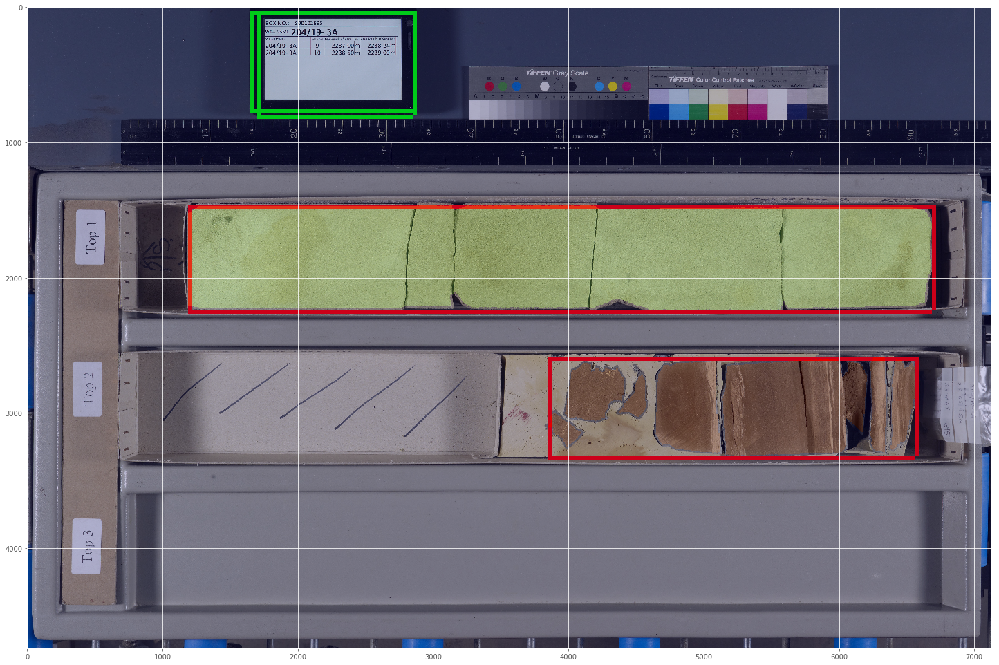

[0 1 6]
[0 1 6]


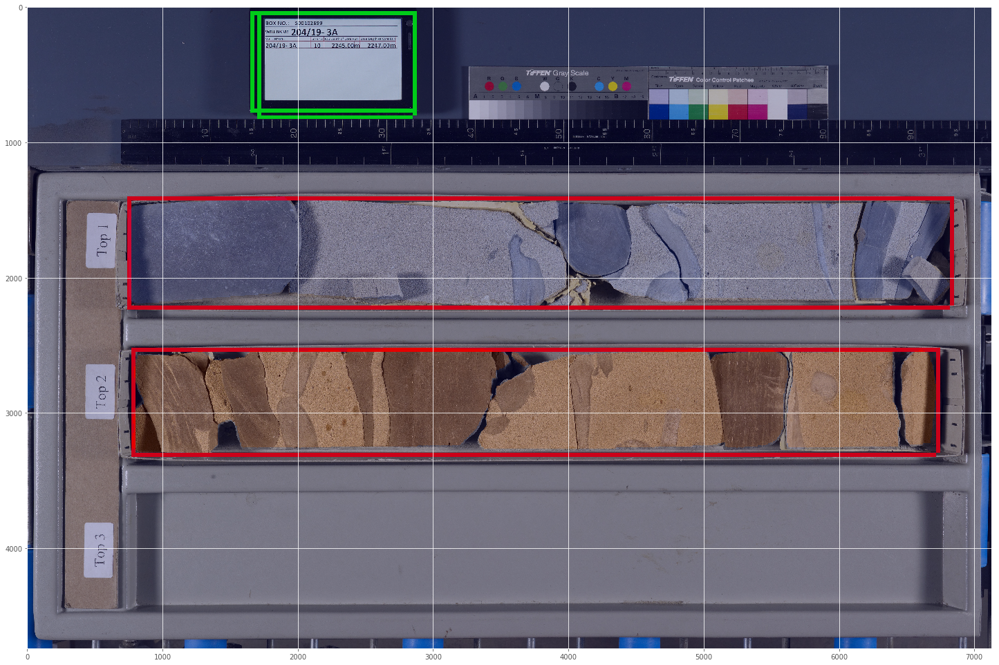

[0 1 3]
[0 1 3]


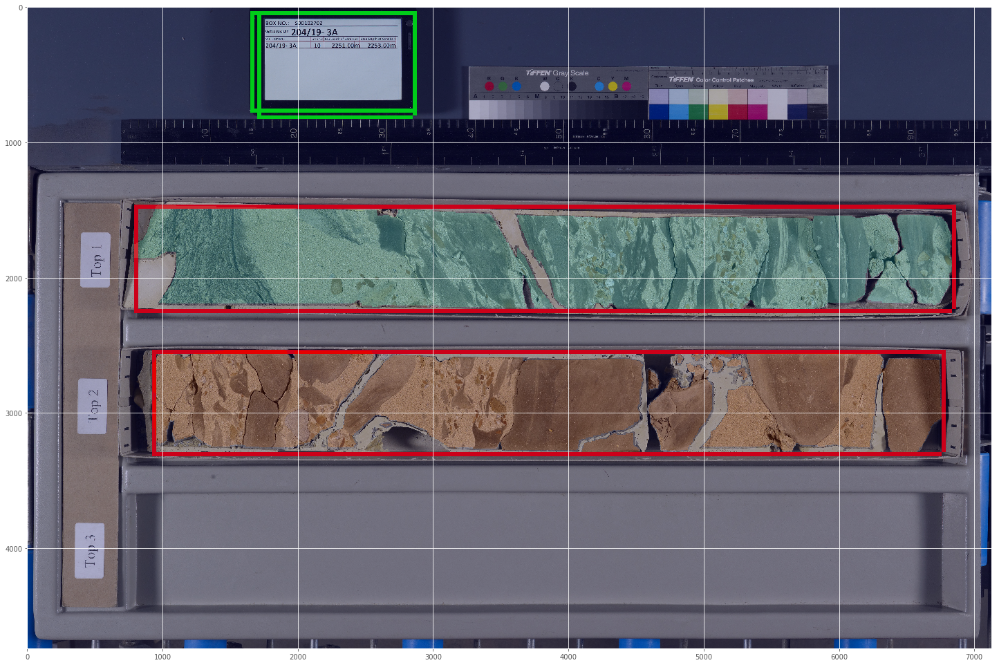

[0 1 5]
[0 1 5]


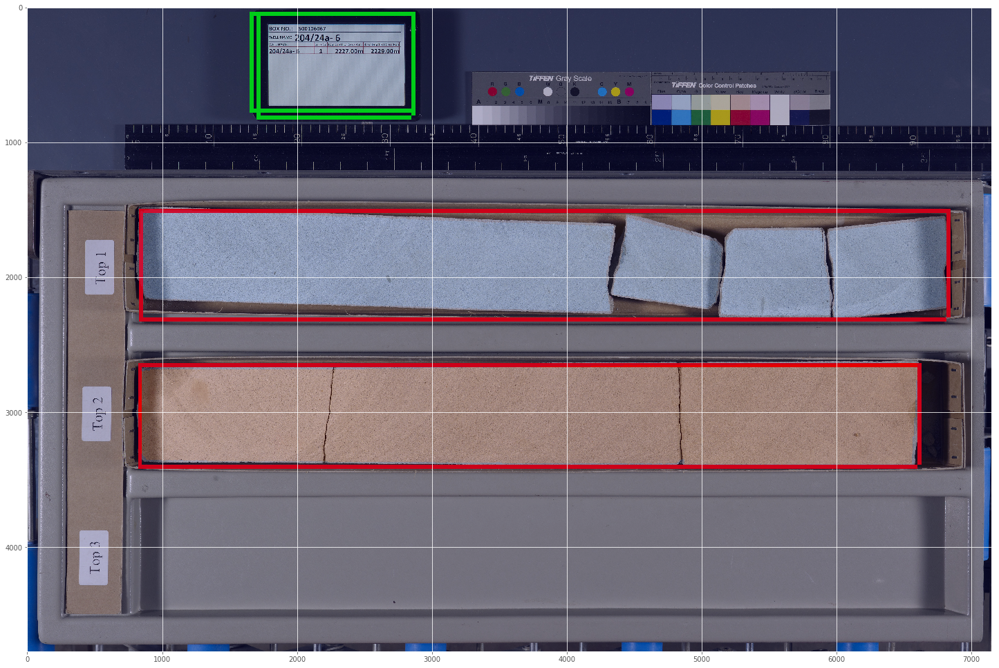

[0 1]
[0 1]


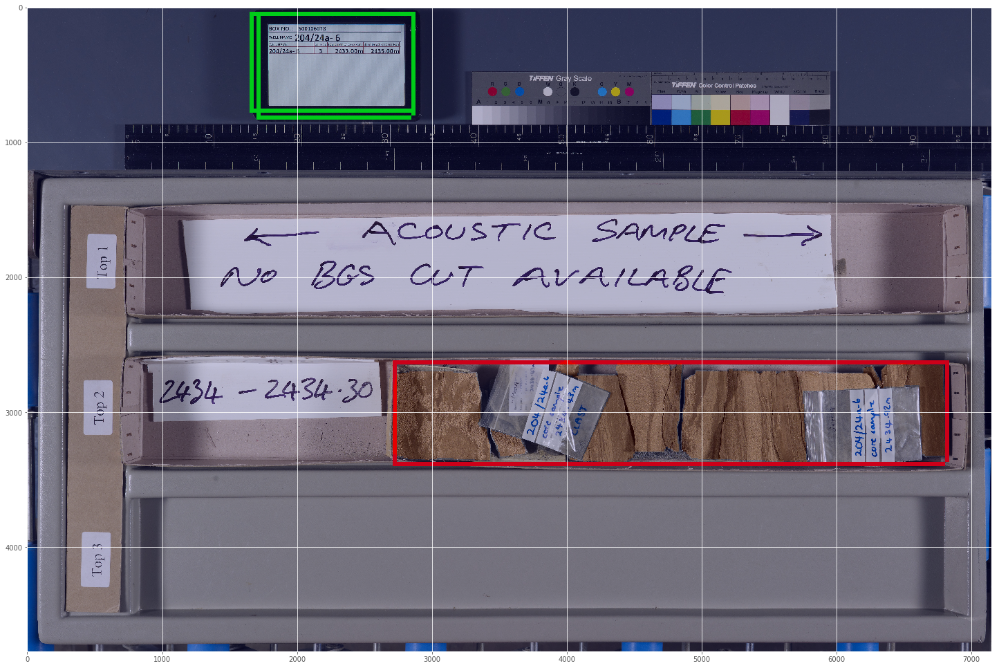

[0 1 3]
[0 1 3]


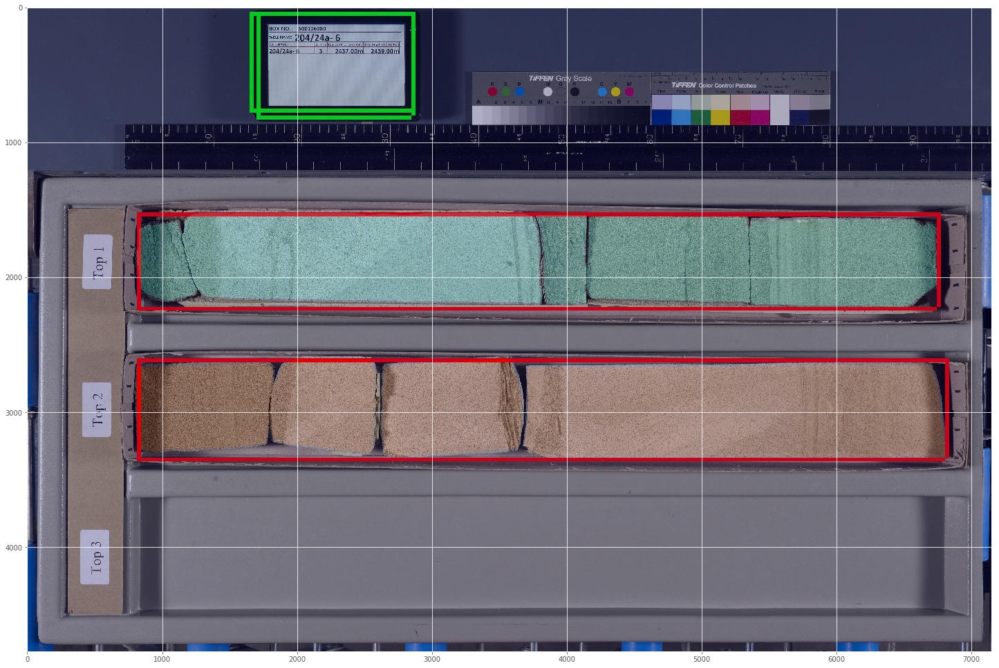

[0 1 2]
[0 1 2]


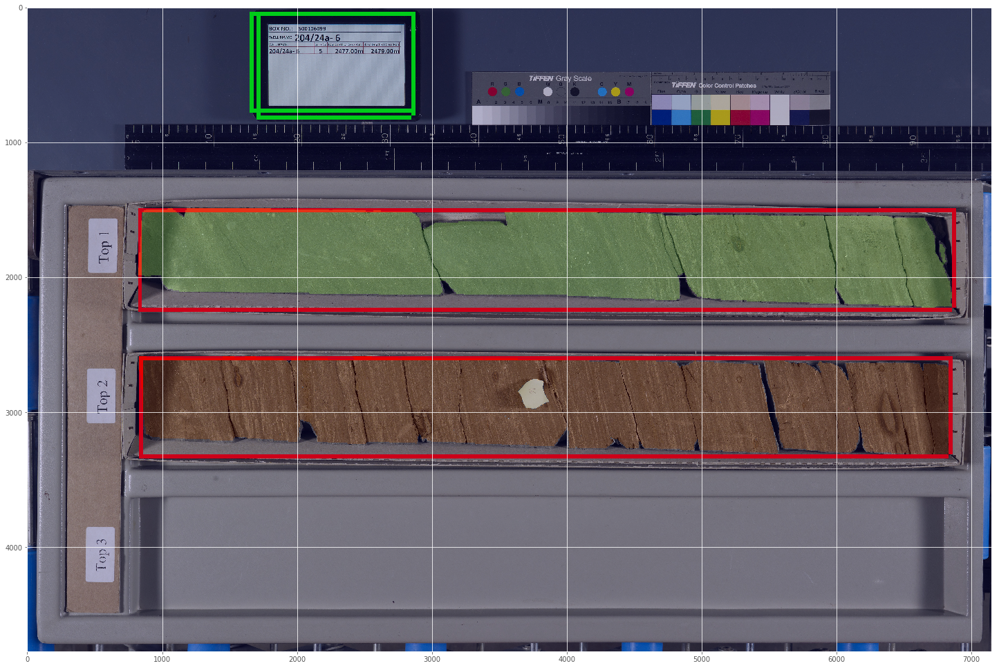

[0 1 2 4]
[0 1 2 4]


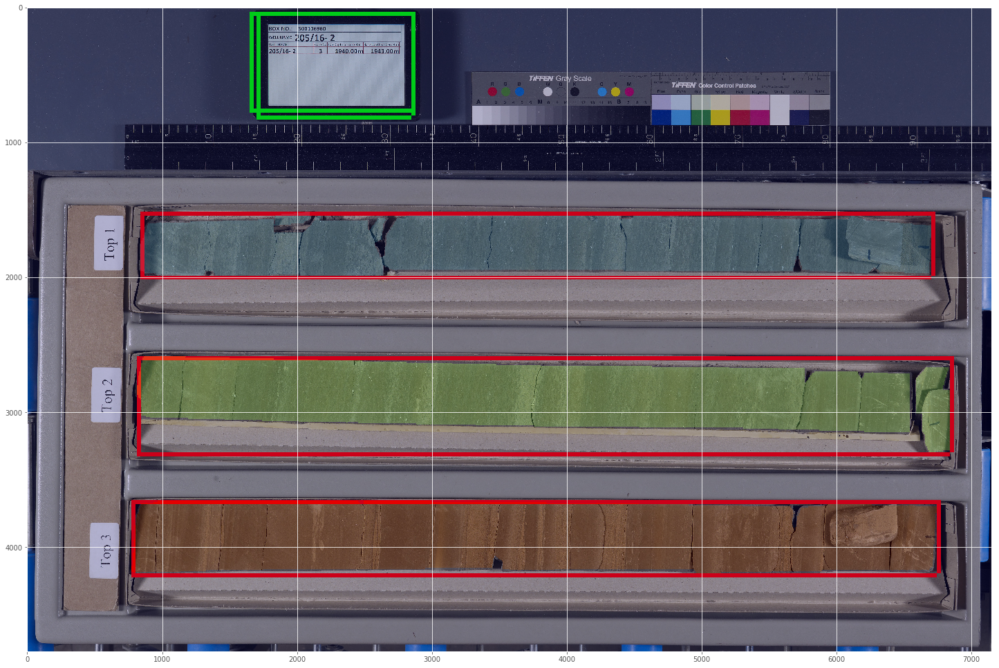

[0 1 4]
[0 1 4]


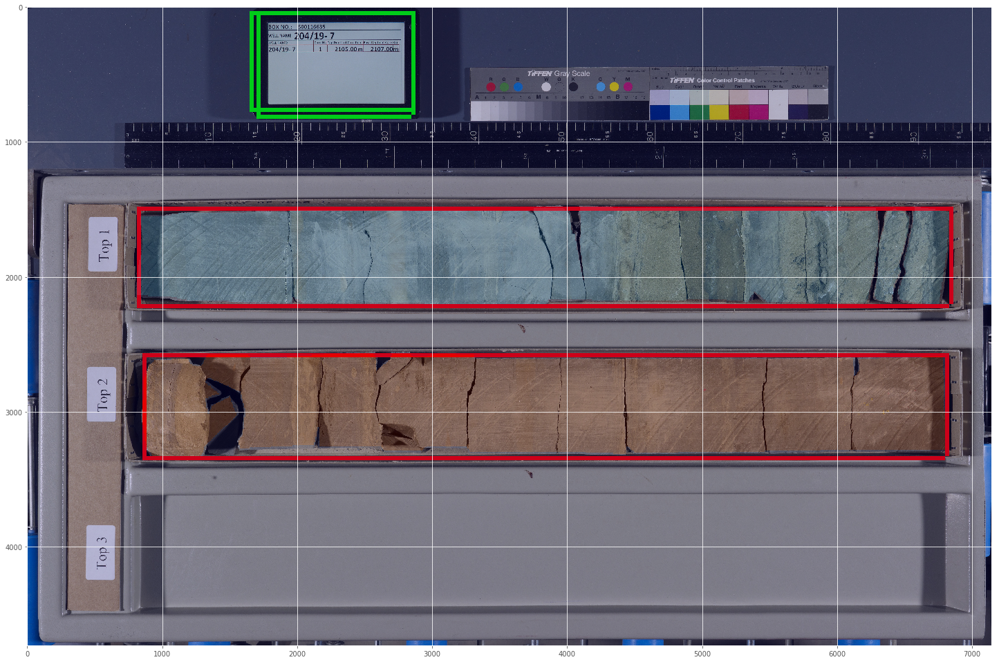

[0 1 2]
[0 1 2]


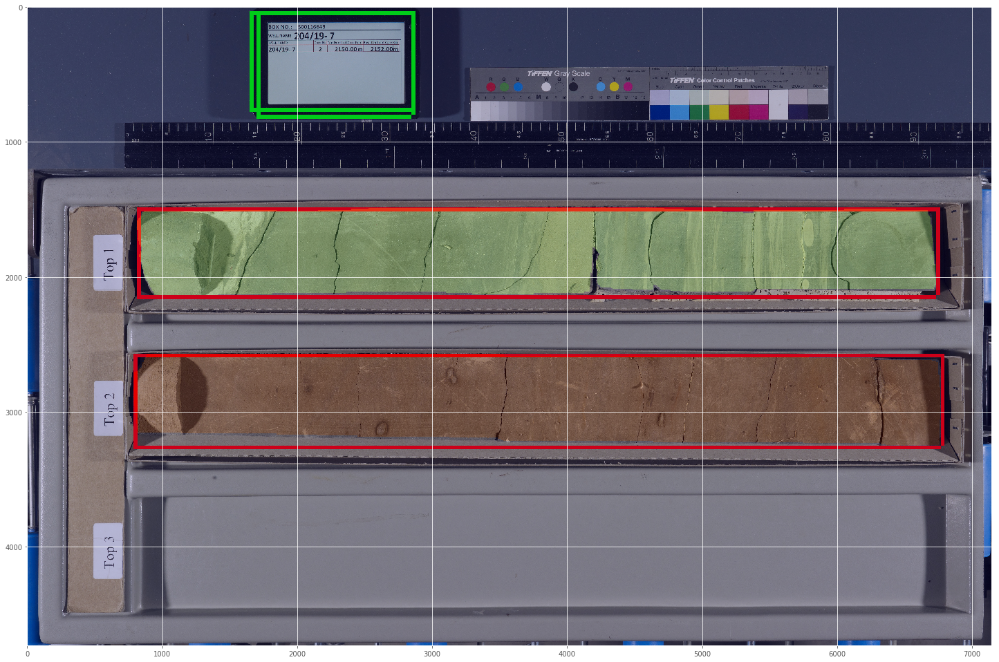

[0 1]
[0 1]


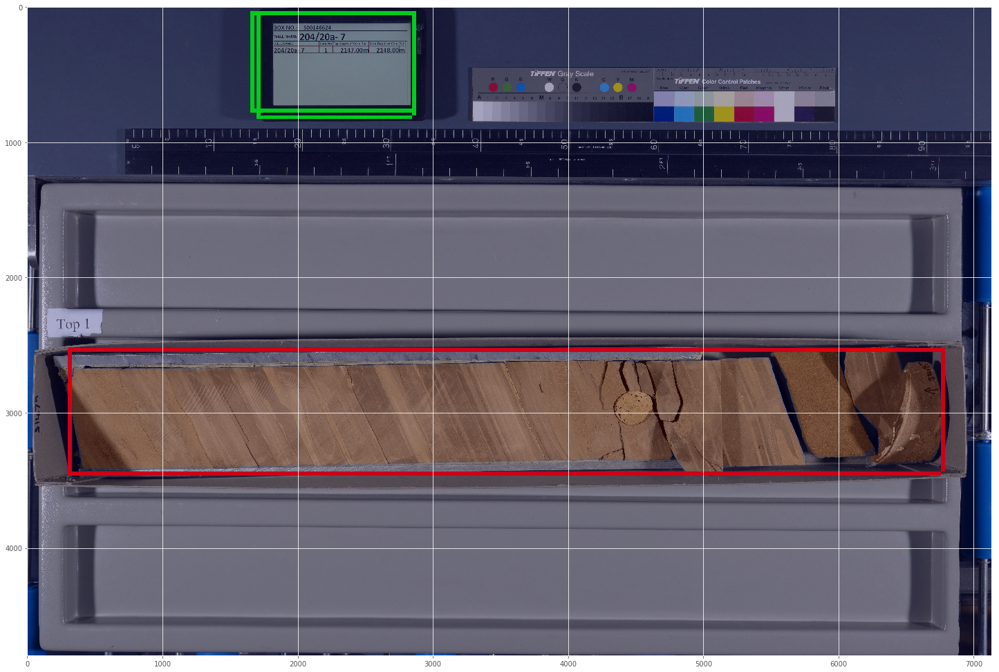

[0 1]
[0 1]


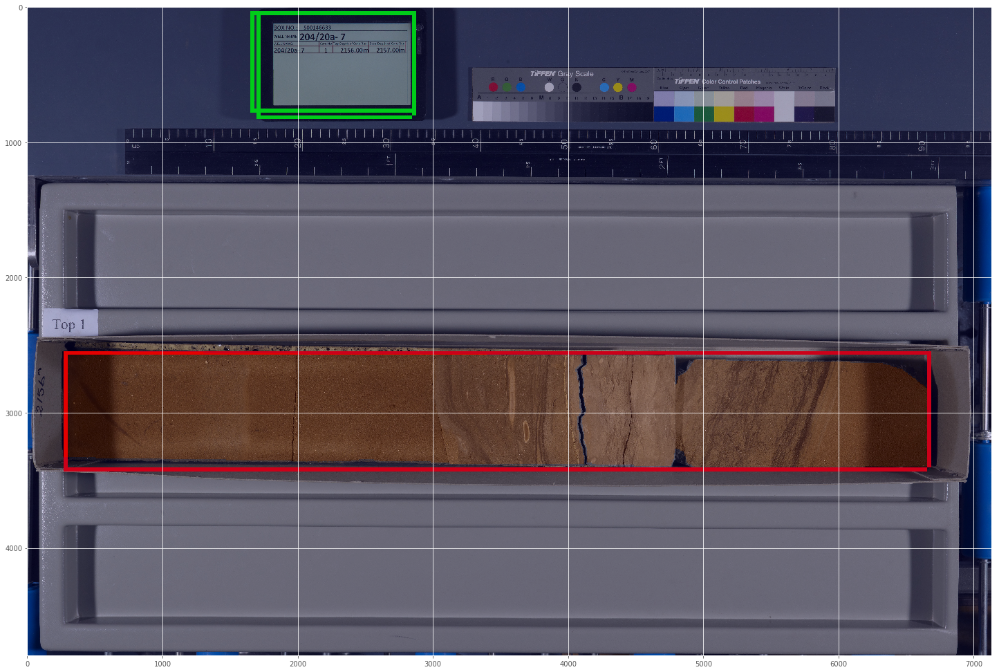

[0 1]
[0 1]


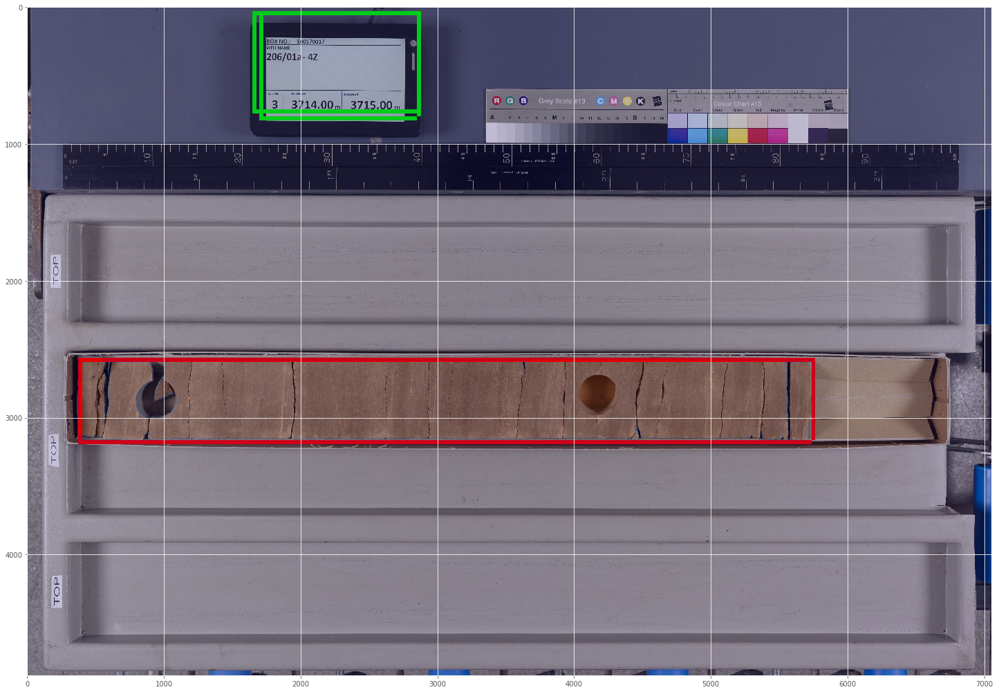

In [78]:
from itertools import combinations

def op(m):
    image = morphology.remove_small_holes(m, area_threshold=1000)
    image = morphology.remove_small_objects(m, min_size=500)
    return image

def overlapping(r0, r1):
    """Check if r0 & r1 are vertically overlapping."""
    if r0.bbox[0] < r1.bbox[2] and r0.bbox[2] > r1.bbox[0]:
        return True
    else:
        return False
    
def squeeze_labels(mask):
    """set labels to range(0, objects+1)"""
    labels = np.unique([r.label for r in measure.regionprops(mask)])
    
    for new_label, label in zip(range(1, labels.size), labels[1:]):
        mask[mask==label] == new_label
        
    return mask
    
    


for cimg, limg in zip(core_imgs, label_imgs):
    mask = measure.label(generate_mask(limg, (0,0,254), morph_op=op), background=0)
    init_regions = measure.regionprops(mask)

    for r0, r1 in combinations(init_regions, 2):
        if overlapping(r0, r1):
            mask[mask==r1.label] = r0.label
        
    box_img = cimg
    for r in measure.regionprops(mask):
        box_img = draw_box(box_img, r.bbox, (255,0,0), 30)
        
    # tv
    box_img = draw_box(box_img, [30,1700,800,2850], (0,255,0), 30)
        
    print(np.unique(mask))
    mask = squeeze_labels(mask)
    print(np.unique(mask))
    
    plt.figure(figsize=(25,25))
    plt.imshow(box_img)
    plt.imshow(mask, cmap='jet', alpha=0.2)
    plt.show()
    
    #if True:
    #   break

In [75]:
from mrcnn.utils import Dataset

class CoreColumnDataset(Dataset):
    
    def load_core_images(self, data_dir, subset):
        
        self.add_class("core", 1, "core_column")
        self.add_class("core", 2, "info_tablet")
        
        assert subset in ['train', 'val']:
        data_dir = os.path.join(dataset_dir, subset)
        
        # 
            
        return
    
    def load_mask(self, image_id):
        image_info = self.image_info[image_id]
        
    

In [77]:
np.unique(mask)

array([0, 1])